# Intervalo de confianza para la longitud media

La varianza poblacional es conocida: $\sigma^2=1.69\;\text{m}^2$, por lo tanto $\sigma=1.3\;\text{m}$. La muestra es $20.2, 21.0, 21.4, 22.1, 23.3$ m, con $n=5$.

## Paso a paso

1. **Media muestral:** $\bar{x}=(20.2+21.0+21.4+22.1+23.3)/5=21.6\;\text{m}$.
2. **Desviación estándar poblacional:** $\sigma=\sqrt{1.69}=1.3\;\text{m}$.
3. **Error estándar:** $\sigma_{\bar{x}}=\sigma/\sqrt{n}=1.3/\sqrt{5}\approx0.5814\;\text{m}$.
4. Como la población es normal y se conoce su desviación estándar, usamos el intervalo Z bilateral: $$\bar{x}\pm z_{1-\alpha/2}\frac{\sigma}{\sqrt{n}}$$
5. Calculamos el valor crítico, el margen de error $E=z_{1-\alpha/2}\sigma/\sqrt{n}$ y los límites $\bar{x}-E$ y $\bar{x}+E$.

### a) $\alpha=10\%$

El nivel de confianza es $1-0.10=0.90$ (90 %) y $z_{0.95}\approx1.6449$.

### b) $\alpha=6\%$

El nivel de confianza es $1-0.06=0.94$ (94 %) y $z_{0.97}\approx1.8808$.

La celda siguiente obtiene los límites con precisión completa e ilustra ambos intervalos en la curva normal. El intervalo del 94 % será más ancho que el del 90 %, porque se requiere mayor confianza.

Confianza: 90% (alpha = 10%)
  z crítico = 1.644854
  Margen de error = 0.9563 m
  IC para mu = (20.6437, 22.5563) m

Confianza: 94% (alpha = 6%)
  z crítico = 1.880794
  Margen de error = 1.0935 m
  IC para mu = (20.5065, 22.6935) m



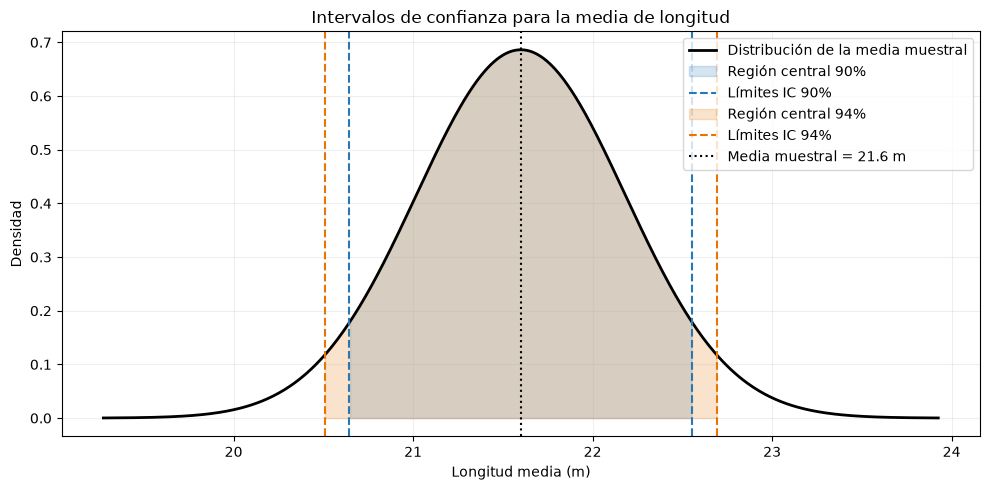

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

datos = np.array([20.2, 21.0, 21.4, 22.1, 23.3])
n = len(datos)
media = datos.mean()
varianza_poblacional = 1.69
sigma = np.sqrt(varianza_poblacional)
error_estandar = sigma / np.sqrt(n)

resultados = []
for alpha in (0.10, 0.06):
    confianza = 1 - alpha
    z_critico = norm.ppf(1 - alpha / 2)
    margen = z_critico * error_estandar
    inferior = media - margen
    superior = media + margen
    resultados.append((confianza, z_critico, margen, inferior, superior))
    print(f"Confianza: {confianza:.0%} (alpha = {alpha:.0%})")
    print(f"  z crítico = {z_critico:.6f}")
    print(f"  Margen de error = {margen:.4f} m")
    print(f"  IC para mu = ({inferior:.4f}, {superior:.4f}) m\n")

x = np.linspace(media - 4 * error_estandar, media + 4 * error_estandar, 600)
densidad = norm.pdf(x, loc=media, scale=error_estandar)
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(x, densidad, color="black", linewidth=2, label="Distribución de la media muestral")

colores = ["#2878B5", "#E87500"]
for (confianza, z_critico, margen, inferior, superior), color in zip(resultados, colores):
    dentro = (x >= inferior) & (x <= superior)
    ax.fill_between(x, 0, densidad, where=dentro, color=color, alpha=0.20,
                    label=f"Región central {confianza:.0%}")
    ax.axvline(inferior, color=color, linestyle="--", linewidth=1.5)
    ax.axvline(superior, color=color, linestyle="--", linewidth=1.5,
               label=f"Límites IC {confianza:.0%}")

ax.axvline(media, color="black", linestyle=":", linewidth=1.5, label=f"Media muestral = {media:.1f} m")
ax.set_title("Intervalos de confianza para la media de longitud")
ax.set_xlabel("Longitud media (m)")
ax.set_ylabel("Densidad")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()